# Week 10 Reproducible preparation and descriptive research
**Research Method of Data Science · TIC3002 · Iegor Vyshnevskyi · Fall 2026**

**Research question:** How do GDP per capita, life expectancy, and internet use differ across selected countries, and how have their patterns changed from 2000 to 2023?

All numerical examples use **real World Bank API responses**, retrieved on **31 October 2026**, embedded unchanged in this notebook with a retrieval manifest. They are not simulated data. There are 27 purposefully selected countries and 24 years. This is a teaching selection, not a representative sample of the world.

**Goals:** preserve raw responses, prepare tidy data, join safely, inspect missingness, describe a stated sample, make progressively richer plots, and export a transparent pipeline.

**Core class route:** Sections 0–6 and 8. **Stretch/reference:** Section 7. **Your project:** Section 9. You can run every code cell from top to bottom. Source data need no separate download and the default run makes no network requests. Optional API refresh is in Section 1.

**Requirements:** Python 3, pandas, numpy, matplotlib, seaborn. Google Colab normally supplies these. In a local Jupyter environment, install any missing packages in that environment. No paid tools or API key required. The optional profiling package is not needed.

**Colab:** open https://colab.research.google.com/, use File → Upload notebook, choose this file, and save a personal copy in Drive. Use Shift+Enter to run a cell. Double-click markdown answer cells to write. Session files are temporary, so download the output bundle and save the completed notebook.

The analysis describes country-level patterns. It does not identify individual effects or show that internet use or income causes longer life.


## 0 Setup and the real API snapshot
Run the setup. The compressed text below packages the actual API response files and their manifest; you do not need to edit it. It restores the same source bytes on every run. A hash check will stop if the restored bytes disagree with the manifest.

Files go into `w10_lab/raw_snapshot/`, `prepared/`, `documentation/`, and `outputs/`. The pipeline keeps source responses separate from prepared tables. This notebook exports no private student data.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from urllib.request import urlopen, Request
from urllib.parse import urlencode
import base64, zlib, json, hashlib, sys, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd() / "w10_lab"
RAW = ROOT / "raw_snapshot"
PREP = ROOT / "prepared"
DOCS = ROOT / "documentation"
FIGS = ROOT / "outputs"
for folder in [RAW, PREP, DOCS, FIGS]:
    folder.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})
print("Working folder:", ROOT)
print("Python", sys.version.split()[0], "pandas", pd.__version__, "seaborn", sns.__version__)


Working folder: c:\Users\vyshn\OneDrive - kdis.ac.kr\Documents\GitHub\Sogang\2026\Fall\Research Method of Data Science\W10\w10_lab
Python 3.13.4 pandas 2.3.0 seaborn 0.13.2


In [2]:
SNAPSHOT_B64 = "..."
restored = json.loads(zlib.decompress(base64.b64decode(SNAPSHOT_B64)).decode())
for filename, content in restored.items():
    (RAW / filename).write_bytes(content.encode("utf-8"))
manifest = json.loads((RAW / "manifest.json").read_text())
for entry in manifest["records"]:
    actual_hash = hashlib.sha256((RAW / entry["file"]).read_bytes()).hexdigest()
    assert actual_hash == entry["sha256"], "Snapshot hash mismatch: " + entry["file"]
COUNTRIES = manifest["countries"]
INDICATORS = manifest["indicators"]
YEARS = list(range(2000, 2024))
ANALYSIS_YEAR = 2023
KEY = ["country_code", "year"]
VALUES = ["gdp_pc_ppp", "life_expectancy", "internet_pct"]
LABELS = {"gdp_pc_ppp": "GDP per capita, PPP (constant 2021 international $)",
          "life_expectancy": "Life expectancy at birth (years)",
          "internet_pct": "Internet use (% of population)"}
SHORT = {"gdp_pc_ppp": "GDP per capita, PPP", "life_expectancy": "Life expectancy (years)",
         "internet_pct": "Internet use (%)"}
print("Verified genuine API response files:", len(manifest["records"]))
print("Countries:", len(COUNTRIES), "Years:", min(YEARS), "to", max(YEARS))
print("Retrieval example:", manifest["records"][0]["retrieved_utc"])


Verified genuine API response files: 6
Countries: 27 Years: 2000 to 2023
Retrieval example: 2026-10-31T01:57:13.814066+00:00


## 1 Source meaning and optional API refresh
| Variable | World Bank indicator | Interpretation |
|---|---|---|
| `gdp_pc_ppp` | `NY.GDP.PCAP.PP.KD` | GDP per person adjusted for purchasing power and expressed in constant 2021 international dollars. Not a household income measure. |
| `life_expectancy` | `SP.DYN.LE00.IN` | Period life expectancy at birth based on prevailing mortality patterns. Not a forecast of each newborn’s actual lifetime. |
| `internet_pct` | `IT.NET.USER.ZS` | Share of people using the internet under the provider’s definition. Not a count of devices or a measure of AI use. |

The API metadata identify underlying providers. Indicator pages display **CC BY 4.0**; preserve attribution to the World Bank/WDI and relevant original providers. Review dataset-specific terms and exceptions before a new use. Metadata and query URLs are retained in the snapshot.

**Optional refresh:** leave `REFRESH_API=False` for the reproducible class snapshot. If enabled, the next cell fetches all response pages and metadata, validates their schema/counts, and writes a *separate* `raw_live/` directory. It does not silently replace the class snapshot. Different retrieval dates can produce revised values.


In [3]:
REFRESH_API = False

def api_pages(base_url, params, fetch=None):
    """Return records and exact raw response pages with provenance."""
    if fetch is None:
        def fetch(url):
            request = Request(url, headers={"User-Agent": "TIC3002 educational example"})
            with urlopen(request, timeout=30) as response:
                return response.read()
    rows, pages = [], []
    page = 1
    while True:
        url = base_url + "?" + urlencode({**params, "page": page})
        body = fetch(url)
        payload = json.loads(body)
        if not (isinstance(payload, list) and len(payload) == 2
                and isinstance(payload[0], dict) and isinstance(payload[1], list)):
            raise ValueError("Unexpected API schema or error response")
        meta, records = payload
        if int(meta["page"]) != page or not 1 <= int(meta["pages"]) <= 20:
            raise ValueError("Unexpected pagination")
        rows.extend(records)
        pages.append({"url": url, "body": body, "response_metadata": meta,
                      "retrieved_utc": datetime.now(timezone.utc).isoformat()})
        if page == int(meta["pages"]):
            if len(rows) != int(meta["total"]):
                raise ValueError("Incomplete response count")
            break
        page += 1
    return rows, pages

if REFRESH_API:
    live_dir = ROOT / "raw_live"
    live_dir.mkdir(exist_ok=True)
    live_manifest = {k: v for k, v in manifest.items() if k != "records"}
    live_manifest["records"] = []
    try:
        for indicator, variable in INDICATORS.items():
            base = "https://api.worldbank.org/v2/country/" + ";".join(COUNTRIES) + "/indicator/" + indicator
            _, pages = api_pages(base, {"source": 2, "date": "2000:2023", "format": "json", "per_page": 1000})
            _, metadata_pages = api_pages("https://api.worldbank.org/v2/indicator/" + indicator,
                                          {"source": 2, "format": "json"})
            for kind, collection in [("data", pages), ("metadata", metadata_pages)]:
                for number, item in enumerate(collection, start=1):
                    name = f"{variable}_{kind}_page_{number}.json"
                    (live_dir / name).write_bytes(item["body"])
                    live_manifest["records"].append({k: v for k, v in item.items() if k != "body"} | {
                        "file": name, "kind": kind, "variable": variable,
                        "sha256": hashlib.sha256(item["body"]).hexdigest()})
        (live_dir / "manifest.json").write_text(json.dumps(live_manifest, indent=2), encoding="utf-8")
        print("Complete live snapshot saved separately in", live_dir)
        print("Class analysis below still uses the embedded snapshot. Compare versions before switching.")
    except Exception as exc:
        print("Live collection incomplete:", type(exc).__name__, str(exc))
        print("Do not treat partial raw_live files as a completed dataset. Class snapshot remains available.")
else:
    print("Using the verified class API snapshot. No network request made.")


Using the verified class API snapshot. No network request made.


## 2 Parse and prepare tidy data
An API record becomes one row per **country-year-indicator** in a long table. The analysis table will have one row per **country-year**, with separate columns for the three measurements. Both are useful structures; the correct observation unit depends on the task.

We check keys and numeric parsing before reshaping. `pivot` requires unique keys; silently averaging repeated records with `pivot_table` would conceal an unresolved duplicate.

**Prediction:** 27 countries × 24 years × 3 indicators = how many long rows? How many country-year rows?


In [4]:
def parse_snapshot(raw_dir):
    """Parse original API pages, preserving provider missing values and notes."""
    info = json.loads((raw_dir / "manifest.json").read_text())
    observations = []
    for entry in info["records"]:
        if entry.get("kind") in {"indicator_metadata", "metadata"}:
            continue
        payload = json.loads((raw_dir / entry["file"]).read_text())
        for record in payload[1]:
            observations.append({
                "country_code": record["countryiso3code"],
                "country": record["country"]["value"],
                "year": record["date"],
                "indicator": record["indicator"]["id"],
                "value": record["value"],
                "provider_status": record.get("obs_status", ""),
                "provider_unit": record.get("unit", ""),
            })
    data = pd.DataFrame(observations)
    if data[["country_code", "year", "indicator"]].isna().any().any():
        raise ValueError("Missing observation key")
    data["year"] = pd.to_numeric(data["year"], errors="raise").astype(int)
    data["value"] = pd.to_numeric(data["value"], errors="raise")
    if data.duplicated(["country_code", "year", "indicator"]).any():
        raise ValueError("Duplicate long-table key; investigate source before reshaping")
    return data.sort_values(["country_code", "year", "indicator"]).reset_index(drop=True)

long = parse_snapshot(RAW)
assert set(long["country_code"]) == set(COUNTRIES)
assert set(long["indicator"]) == set(INDICATORS)
print("Long shape:", long.shape)
print(long.head(6).to_string(index=False))
wide = long.pivot(index=KEY, columns="indicator", values="value").rename(columns=INDICATORS).reset_index()
wide.columns.name = None
names = long[["country_code", "country"]].drop_duplicates()
assert not names.duplicated("country_code").any()
wide = wide.merge(names, on="country_code", how="left", validate="many_to_one")
wide = wide[KEY + ["country"] + VALUES].sort_values(KEY).reset_index(drop=True)
print("\nWide shape:", wide.shape)
print(wide.head().to_string(index=False))


Long shape: (1944, 7)
country_code     country  year         indicator       value provider_status provider_unit
         AFG Afghanistan  2000    IT.NET.USER.ZS         NaN                              
         AFG Afghanistan  2000 NY.GDP.PCAP.PP.KD 1617.826475                              
         AFG Afghanistan  2000    SP.DYN.LE00.IN   55.005000                              
         AFG Afghanistan  2001    IT.NET.USER.ZS    0.004723                              
         AFG Afghanistan  2001 NY.GDP.PCAP.PP.KD 1454.110782                              
         AFG Afghanistan  2001    SP.DYN.LE00.IN   55.511000                              

Wide shape: (648, 6)
country_code  year     country  gdp_pc_ppp  life_expectancy  internet_pct
         AFG  2000 Afghanistan 1617.826475           55.005           NaN
         AFG  2001 Afghanistan 1454.110782           55.511      0.004723
         AFG  2002 Afghanistan 1774.308743           56.225      0.004561
         AFG  2003 Afgh

### 2A Joins need the full key
Split the actual API records into GDP and life-expectancy tables. Joining on country alone combines every year on the left with every year on the right. No values are invented here; the error arises from combining real records with an incomplete key.

The wrong demonstration uses Korea only, keeping the accidental product small. A validated one-to-one join catches it. All errors shown below are deliberately caught so Run All continues.


In [5]:
gdp = long.loc[long.indicator == "NY.GDP.PCAP.PP.KD", KEY + ["value"]].rename(columns={"value": "gdp_pc_ppp"})
life = long.loc[long.indicator == "SP.DYN.LE00.IN", KEY + ["value"]].rename(columns={"value": "life_expectancy"})
gdp_kor = gdp.loc[gdp.country_code == "KOR"]
life_kor = life.loc[life.country_code == "KOR"]
wrong_join = gdp_kor.merge(life_kor, on="country_code")
print("Wrong country-only join:", len(wrong_join), "rows instead of", len(gdp_kor))
try:
    gdp_kor.merge(life_kor, on="country_code", validate="one_to_one")
except pd.errors.MergeError:
    print("Validated join rejected the nonunique country key, as intended.")
joined = gdp.merge(life, on=KEY, how="outer", validate="one_to_one", indicator=True)
print("Correct join shape:", joined.shape)
print("Join coverage:\n", joined["_merge"].value_counts().to_string())
print("Matched keys can still contain missing measurements:", int(joined["gdp_pc_ppp"].isna().sum()))


Wrong country-only join: 576 rows instead of 24
Validated join rejected the nonunique country key, as intended.
Correct join shape: (648, 5)
Join coverage:
 _merge
both          648
left_only       0
right_only      0
Matched keys can still contain missing measurements: 48


**Checkpoint A — your answer:** Explain why “both” in the join-coverage column does not mean both measurements are available. State the correct key and the row count you expect. Replace this paragraph with your answer.


## 3 Missingness and a defensible preparation policy
The API supplies records with `null` measurements. Missing values remain missing. We do not invent a numerical missing code, replace blanks with zero, or automatically interpolate across interruptions.

**Class policy:** retain all country-years in the prepared panel. A plot or statistic uses the variables and year it actually needs, and reports its usable sample. Keep full and complete-case counts visible. Do not globally delete a country because one variable is unavailable.

The provider’s absence does not establish the reason for missingness. Check its metadata before claiming that a gap results from conflict, collection failure, or another mechanism.


In [6]:
def validate_panel(data):
    expected = pd.MultiIndex.from_product([COUNTRIES, YEARS], names=KEY)
    actual = pd.MultiIndex.from_frame(data[KEY])
    rules = {
        "country-year key unique": not data.duplicated(KEY).any(),
        "country-year keys present": not data[KEY].isna().any().any(),
        "expected grid present": len(expected.difference(actual)) == 0,
        "no unexpected keys": len(actual.difference(expected)) == 0,
        "observed GDP per capita positive": data["gdp_pc_ppp"].dropna().gt(0).all(),
        "observed life expectancy within a broad plausibility bound": data["life_expectancy"].dropna().between(0, 120).all(),
        "observed internet share within 0 to 100": data["internet_pct"].dropna().between(0, 100).all(),
    }
    return pd.DataFrame({"rule": list(rules), "passes": list(rules.values())})

checks = validate_panel(wide)
print(checks.to_string(index=False))
if not checks["passes"].all():
    raise ValueError("A validation rule failed; investigate rather than silently fixing values")
missing = pd.DataFrame({"n_missing": wide[VALUES].isna().sum(),
                        "missing_pct": wide[VALUES].isna().mean() * 100})
print("\nMissingness in the full panel:\n", missing.to_string())
print("\nMissing cells by country:\n", wide.groupby("country_code")[VALUES].agg(lambda x: x.isna().sum()).to_string())
latest = wide.loc[wide.year == ANALYSIS_YEAR].copy()
complete = latest.dropna(subset=VALUES).copy()
print("\n2023 countries:", len(latest), "Complete for all three variables:", len(complete))
print("Excluded from joint 2023 analyses:", latest.loc[latest[VALUES].isna().any(axis=1), "country_code"].tolist())


                                                      rule  passes
                                   country-year key unique    True
                                 country-year keys present    True
                                     expected grid present    True
                                        no unexpected keys    True
                          observed GDP per capita positive    True
observed life expectancy within a broad plausibility bound    True
                   observed internet share within 0 to 100    True

Missingness in the full panel:
                  n_missing  missing_pct
gdp_pc_ppp              48     7.407407
life_expectancy          0     0.000000
internet_pct            26     4.012346

Missing cells by country:
               gdp_pc_ppp  life_expectancy  internet_pct
country_code                                           
AFG                    0                0             1
AUS                    0                0             3
BRA                

### 3A Derived measures need units and conditions
The next cell adds natural-log GDP only for positive observations. This helps view a skewed distribution and multiplicative differences. It changes the scale, not the underlying GDP values.

For percentage-point change, subtract two percentages. A change from 20% to 30% is 10 percentage points and 50% relative growth. The following endpoint change uses actual internet-use records; it does not assume every country has both endpoints.


In [7]:
panel = wide.copy(deep=True)
panel["log_gdp_pc_ppp"] = np.log(panel["gdp_pc_ppp"].where(panel["gdp_pc_ppp"] > 0))
endpoints = panel.loc[panel.year.isin([2000, 2023])].pivot(index="country_code", columns="year", values="internet_pct")
endpoints["change_pp_2000_2023"] = endpoints[2023] - endpoints[2000]
print(endpoints.sort_values("change_pp_2000_2023", ascending=False).round(2).to_string())


year           2000   2023  change_pp_2000_2023
country_code                                   
CHN            1.78  90.60                88.82
THA            3.69  89.54                85.85
TUR            3.76  85.96                82.20
ESP           13.62  95.45                81.82
BRA            2.87  84.15                81.28
UKR            0.72  81.58                80.86
POL            7.29  86.41                79.13
VNM            0.25  78.08                77.83
MYS           21.38  97.69                76.31
MEX            5.08  81.18                76.10
PHL            1.98  77.87                75.88
EGY            0.64  74.01                73.37
ZAF            5.35  78.34                72.99
FRA           14.31  86.84                72.53
GBR           26.82  95.45                68.63
IDN            0.93  69.21                68.28
ITA           23.11  87.03                63.92
DEU           30.22  92.48                62.26
IND            0.53  60.25              

**Checkpoint B — your answer:** Which observations disappear from an analysis requiring all three variables in 2023? Is that the same as having missing country-year keys? Explain one risk of filling every missing value with a global mean. Do not attribute missingness to a cause that you have not verified.


## 4 Descriptive statistics from a stated sample
Start with `describe()`, then add a reusable summary with **usable N, missing count, percentiles, standard deviation, IQR and skewness**.

Use the **2023 cross-section** for these comparisons. Pooling every year would count each country repeatedly, mix time periods, and let data availability affect the implicit weights. These are unweighted country summaries, not world population averages.

Mean and median summarize location. Standard deviation and IQR summarize different aspects of spread. A quartile-based outlier flag is a prompt to inspect a value, not proof of an error. Standard deviation here is a sample summary with `ddof=1`; it is not a standard error or confidence interval.


In [8]:
def numeric_summary(data, columns):
    """Descriptive table for explicit measurement columns, never numeric IDs by default."""
    records = []
    for name in columns:
        x = pd.to_numeric(data[name], errors="raise")
        observed = x.dropna()
        q1, q3 = observed.quantile([.25, .75]) if len(observed) else (np.nan, np.nan)
        iqr = q3 - q1
        records.append({
            "variable": name, "rows": len(x), "n": int(x.notna().sum()),
            "missing": int(x.isna().sum()), "missing_pct": x.isna().mean() * 100,
            "unique_observed": observed.nunique(), "mean": observed.mean(),
            "std": observed.std(ddof=1), "min": observed.min(),
            "p05": observed.quantile(.05), "q1": q1, "median": observed.median(),
            "q3": q3, "p95": observed.quantile(.95), "max": observed.max(),
            "iqr": iqr, "skew": observed.skew(),
            "iqr_flags": int(((observed < q1 - 1.5 * iqr) | (observed > q3 + 1.5 * iqr)).sum())
                         if len(observed) else 0,
        })
    return pd.DataFrame(records).set_index("variable")

print("Pandas describe:\n", latest[VALUES].describe().T.round(2).to_string())
summary_2023 = numeric_summary(latest, VALUES)
print("\nExtended numeric summary:\n", summary_2023.round(2).to_string())
summary_2023.to_csv(DOCS / "summary_2023.csv")


Pandas describe:
                  count      mean       std      min       25%       50%       75%       max
gdp_pc_ppp        25.0  34261.01  20942.63  1983.81  15916.96  32857.67  53423.42  74351.67
life_expectancy   27.0     76.00      6.56    57.62     71.82     76.66     81.43     84.04
internet_pct      25.0     82.97     16.77    15.93     78.34     86.41     93.53     97.69

Extended numeric summary:
                  rows   n  missing  missing_pct  unique_observed      mean       std      min      p05        q1    median        q3       p95       max       iqr  skew  iqr_flags
variable                                                                                                                                                                           
gdp_pc_ppp         27  25        2         7.41               25  34261.01  20942.63  1983.81  9076.15  15916.96  32857.67  53423.42  62649.15  74351.67  37506.46  0.22          0
life_expectancy    27  27        0         0.0

## 5 First plots then comparisons
Every plot below uses the actual retrieved API values. Each chart states its units and observation period. Figures save to `outputs/`.

### 5A One country over time
A line is suitable for ordered time. Sorting the years and preserving missing years prevents misleading connections. In this example Korea has observations for the chosen period.


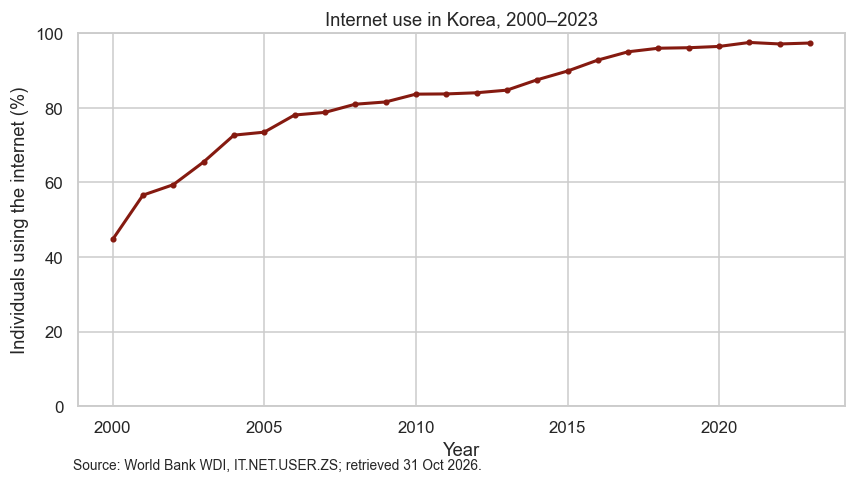

In [9]:
def save_figure(fig, filename):
    fig.savefig(FIGS / filename, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

kor = panel.loc[panel.country_code == "KOR"].set_index("year").reindex(YEARS)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(YEARS, kor["internet_pct"], color="#851a10", linewidth=2, marker="o", markersize=3)
ax.set(title="Internet use in Korea, 2000–2023", xlabel="Year", ylabel="Individuals using the internet (%)", ylim=(0, 100))
fig.text(.12, -.02, "Source: World Bank WDI, IT.NET.USER.ZS; retrieved 31 Oct 2026.", fontsize=9)
save_figure(fig, "01_korea_internet.png")


### 5B A small cross-country comparison
A sorted horizontal bar chart helps compare a small number of named countries. Bars begin at zero because their lengths encode values. Missing observations must be reported rather than plotted as zero.


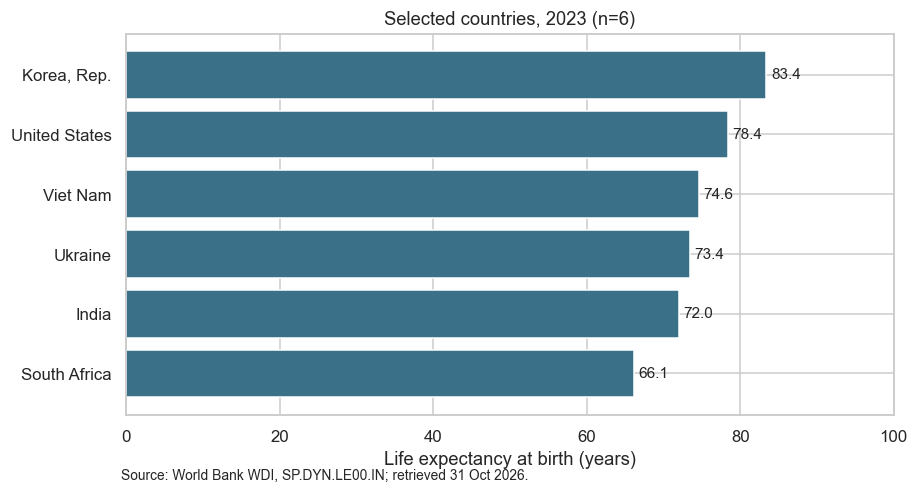

In [10]:
focus_codes = ["KOR", "VNM", "UKR", "USA", "IND", "ZAF"]
focus = latest.loc[latest.country_code.isin(focus_codes), ["country", "life_expectancy"]].dropna().sort_values("life_expectancy")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(focus["country"], focus["life_expectancy"], color="#3a7188")
for i, value in enumerate(focus["life_expectancy"]):
    ax.text(value + .6, i, f"{value:.1f}", va="center", fontsize=10)
ax.set(xlabel="Life expectancy at birth (years)", title=f"Selected countries, 2023 (n={len(focus)})", xlim=(0, 100))
fig.text(.12, -.02, "Source: World Bank WDI, SP.DYN.LE00.IN; retrieved 31 Oct 2026.", fontsize=9)
save_figure(fig, "02_life_bars.png")


### 5C Distribution and scale
Compare the GDP distribution in its original units with the same observations on a natural-log scale. Histograms depend on bin choices, especially with a small teaching sample. Do not read a bar’s height as a probability without checking the normalization.


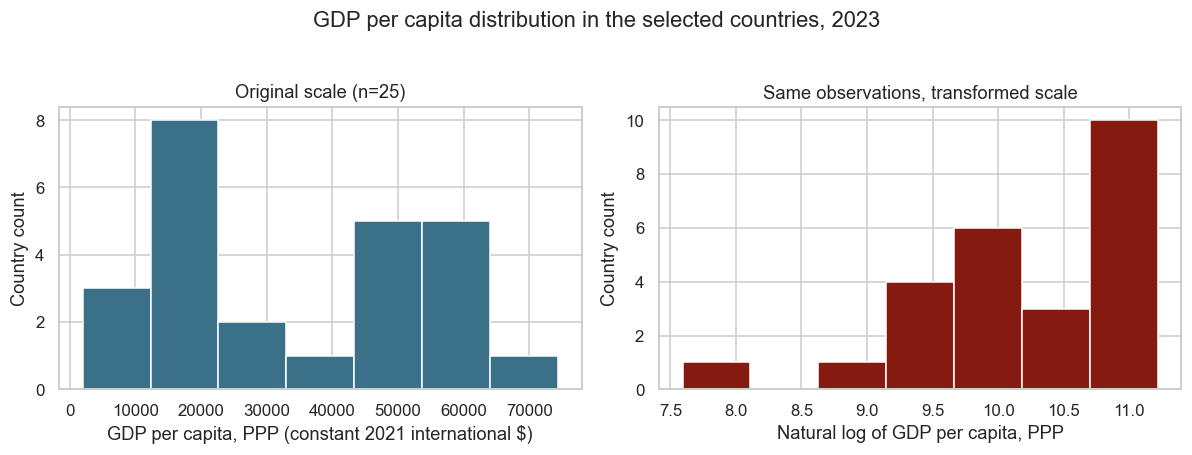

In [11]:
gdp2023 = latest["gdp_pc_ppp"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(gdp2023, bins=7, color="#3a7188", edgecolor="white")
axes[0].set(xlabel="GDP per capita, PPP (constant 2021 international $)", ylabel="Country count", title=f"Original scale (n={len(gdp2023)})")
axes[1].hist(np.log(gdp2023), bins=7, color="#851a10", edgecolor="white")
axes[1].set(xlabel="Natural log of GDP per capita, PPP", ylabel="Country count", title="Same observations, transformed scale")
fig.suptitle("GDP per capita distribution in the selected countries, 2023", y=1.03)
fig.tight_layout()
save_figure(fig, "03_gdp_histograms.png")


### 5D A bivariate plot with a transparent sample
Each point is one country in 2023, not a person. Use only the two required variables here; internet-use missingness need not exclude a country from a GDP–life-expectancy plot. A logarithmic x-axis shows proportional spacing. A curved-looking relationship on one scale may look different on another.

We label only a few points to keep the graphic readable. A visible association does not identify a causal effect.


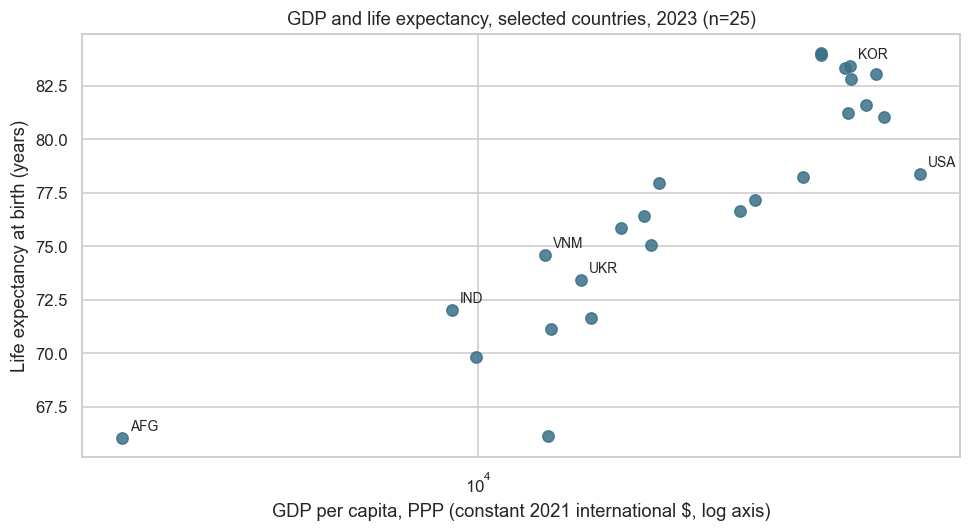

In [12]:
scatter_data = latest.dropna(subset=["gdp_pc_ppp", "life_expectancy"])
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(scatter_data["gdp_pc_ppp"], scatter_data["life_expectancy"], color="#3a7188", s=55, alpha=.85)
for _, row in scatter_data.loc[scatter_data.country_code.isin(["KOR", "VNM", "UKR", "USA", "IND", "AFG"])].iterrows():
    ax.annotate(row.country_code, (row.gdp_pc_ppp, row.life_expectancy), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.set_xscale("log")
ax.set(xlabel="GDP per capita, PPP (constant 2021 international $, log axis)",
       ylabel="Life expectancy at birth (years)", title=f"GDP and life expectancy, selected countries, 2023 (n={len(scatter_data)})")
fig.tight_layout()
save_figure(fig, "04_gdp_life_scatter.png")


**Checkpoint C — your interpretation:** Choose one plot. Write two descriptive sentences naming the unit, period, measure and sample. Then add one limitation. Avoid causal wording. Try changing a visual choice (bin count, country subset, or linear/log x-axis) and explain whether the apparent pattern changes.


## 6 One function for a broad descriptive report
`descriptive_report()` returns a numerical summary, schema, missingness table, Pearson correlations, a pairwise usable-N matrix, and a multi-panel graphical dashboard. It exports CSVs and an HTML report containing the tables and figure.

Choose measurement columns explicitly. Numeric country IDs or years should not automatically enter every histogram and correlation. Pearson correlation describes a linear relationship and can be sensitive to extreme values. The displayed sample is the 2023 cross-section. The report does not test causality or replace checking definitions.

This is the main reusable reporting function for your project. All work stays local to the notebook runtime. No profiling service receives the data.


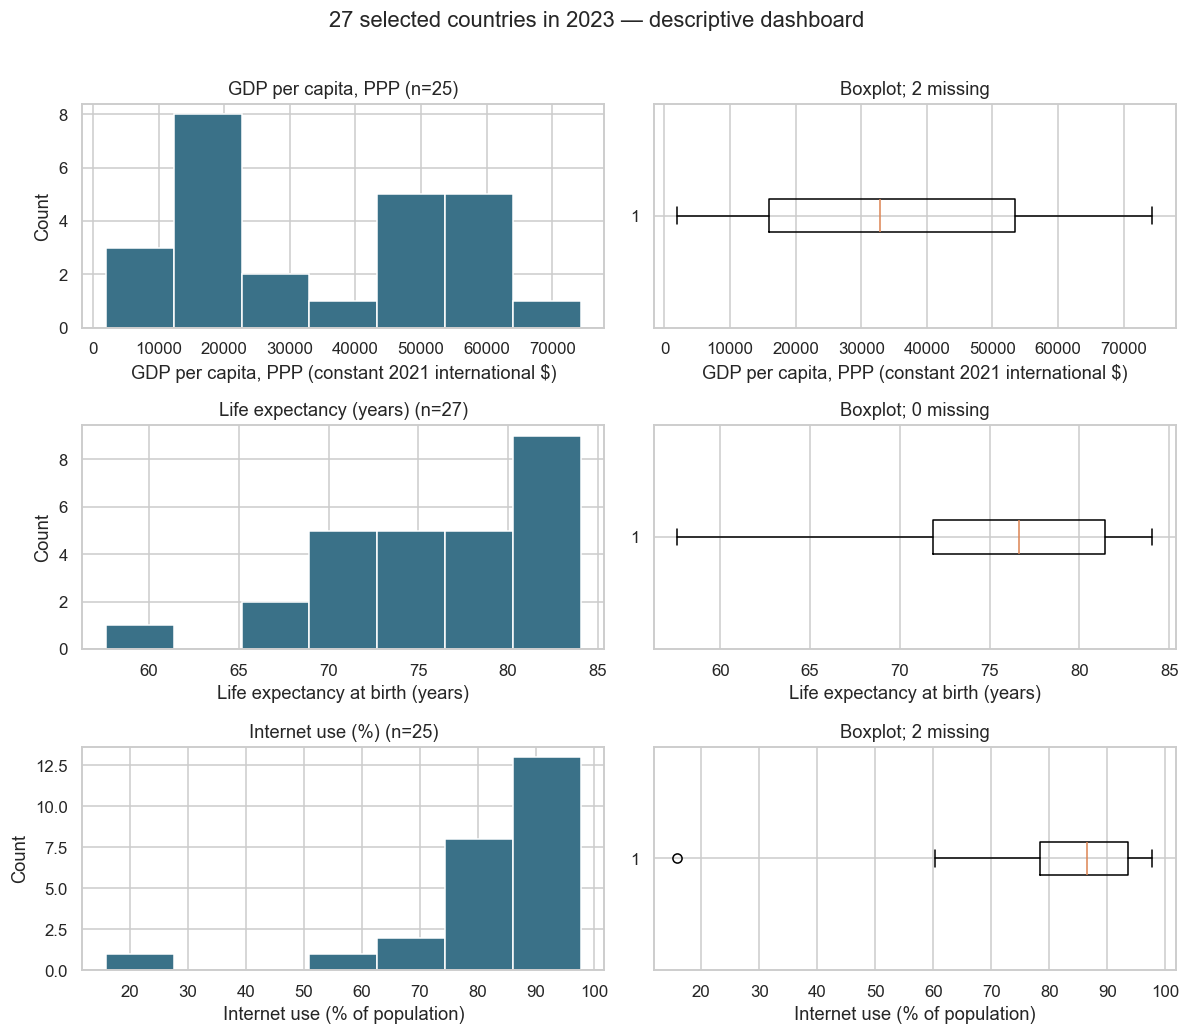

                 rows   n  missing  missing_pct  unique_observed      mean       std      min      p05        q1    median        q3       p95       max       iqr  skew  iqr_flags
variable                                                                                                                                                                           
gdp_pc_ppp         27  25        2         7.41               25  34261.01  20942.63  1983.81  9076.15  15916.96  32857.67  53423.42  62649.15  74351.67  37506.46  0.22          0
life_expectancy    27  27        0         0.00               27     76.00      6.56    57.62    66.07     71.82     76.66     81.43     83.78     84.04      9.61 -0.88          0
internet_pct       27  25        2         7.41               25     82.97     16.77    15.93    62.04     78.34     86.41     93.53     97.16     97.69     15.19 -2.88          1

Pairwise usable N:
                  gdp_pc_ppp  life_expectancy  internet_pct
gdp_pc_ppp          

In [13]:
def descriptive_report(data, columns, label, prefix="descriptive"):
    """Local numerical and graphical EDA for explicit columns and a named sample."""
    from html import escape
    from io import BytesIO
    x = data[columns].apply(pd.to_numeric, errors="raise")
    summary = numeric_summary(data, columns)
    schema = pd.DataFrame({"dtype": data.dtypes.astype(str), "missing": data.isna().sum(),
                           "unique_observed": data.nunique(dropna=True)})
    missing_table = pd.DataFrame({"n_missing": x.isna().sum(), "missing_pct": x.isna().mean() * 100})
    correlation = x.corr(method="pearson", min_periods=3)
    present = x.notna().astype(int)
    pair_n = present.T.dot(present)
    fig, axes = plt.subplots(len(columns), 2, figsize=(11, 3.1 * len(columns)), squeeze=False)
    for i, name in enumerate(columns):
        observed = x[name].dropna()
        axes[i, 0].hist(observed, bins=7, color="#3a7188", edgecolor="white")
        axes[i, 0].set(title=f"{SHORT.get(name, name)} (n={len(observed)})", ylabel="Count")
        axes[i, 1].boxplot(observed.to_numpy(), vert=False)
        axes[i, 1].set(title=f"Boxplot; {int(x[name].isna().sum())} missing")
        for ax in axes[i]:
            ax.set_xlabel(LABELS.get(name, name))
    fig.suptitle(label + " — descriptive dashboard", y=1.01)
    fig.tight_layout()
    image_path = FIGS / f"{prefix}_dashboard.png"
    fig.savefig(image_path, bbox_inches="tight", facecolor="white")
    buffer = BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight", facecolor="white")
    img64 = base64.b64encode(buffer.getvalue()).decode()
    plt.show(); plt.close(fig)
    results = {"summary": summary, "schema": schema, "missing": missing_table,
               "correlation": correlation, "pairwise_n": pair_n}
    for name, table in results.items():
        table.to_csv(DOCS / f"{prefix}_{name}.csv")
    html = ["<!doctype html><meta charset='utf-8'><title>Descriptive report</title>",
            "<style>body{font:16px Arial;margin:40px;max-width:1200px}table{border-collapse:collapse}td,th{padding:7px;border:1px solid #ccc}img{max-width:100%}</style>",
            "<h1>" + escape(label) + "</h1>",
            "<p>Unweighted observations in the named sample. Missing values retained in the source table. Correlations use available pairs; inspect their N. Figures and tables are descriptive.</p>"]
    for name, table in results.items():
        html += ["<h2>" + escape(name.replace("_", " ")) + "</h2>", table.round(3).to_html()]
    html += ["<h2>Distributions</h2><img alt='Histograms and boxplots for the selected measures' src='data:image/png;base64," + img64 + "'>",
             "<p>Source: World Bank, World Development Indicators. Indicator codes and source metadata in the retrieval manifest. Retrieved 31 October 2026.</p>"]
    report_file = DOCS / f"{prefix}_report.html"
    report_file.write_text("\n".join(html), encoding="utf-8")
    print(summary.round(2).to_string())
    print("\nPairwise usable N:\n", pair_n.to_string())
    print("\nLocal HTML report:", report_file)
    results["html_path"] = report_file
    return results

report_2023 = descriptive_report(latest, VALUES, "27 selected countries in 2023", prefix="2023")


### 6A A correlation display needs its sample size
This heatmap uses raw GDP, life expectancy, and internet percentage. It does not use the log axis from the scatterplot. It labels each coefficient with its pairwise usable N. If each pair uses a different set of countries, their correlations are not directly comparable as a fixed-sample matrix.

A constant variable, too few usable records, or unavailable values can produce an undefined correlation. Such cells remain blank.


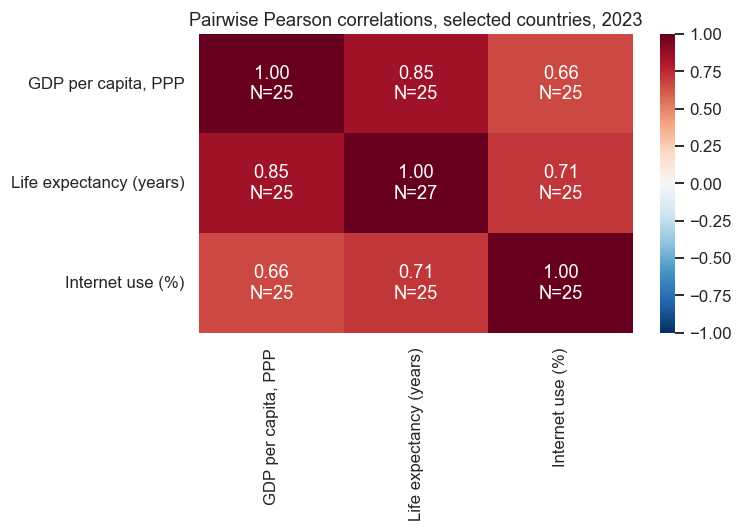

In [14]:
corr = report_2023["correlation"]
pair_n = report_2023["pairwise_n"]
annotations = corr.copy().astype(object)
for row in corr.index:
    for col in corr.columns:
        annotations.loc[row, col] = f"{corr.loc[row, col]:.2f}\nN={pair_n.loc[row, col]}" if pd.notna(corr.loc[row, col]) else ""
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=annotations, fmt="", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            xticklabels=[SHORT[x] for x in VALUES], yticklabels=[SHORT[x] for x in VALUES], ax=ax)
ax.set(title="Pairwise Pearson correlations, selected countries, 2023")
fig.tight_layout()
save_figure(fig, "05_correlation_heatmap.png")


## 7 Stretch plots and exploratory tools
These examples increase the graphical complexity without introducing a new statistical model. They are runnable reference material; you do not need to interpret every plot during Thursday’s core lab.

### 7A A country-by-year missingness map
Colour encodes whether internet use is missing, not the level of use. Row order follows country codes. A gap is a source-coverage question; do not infer its cause from the image alone.


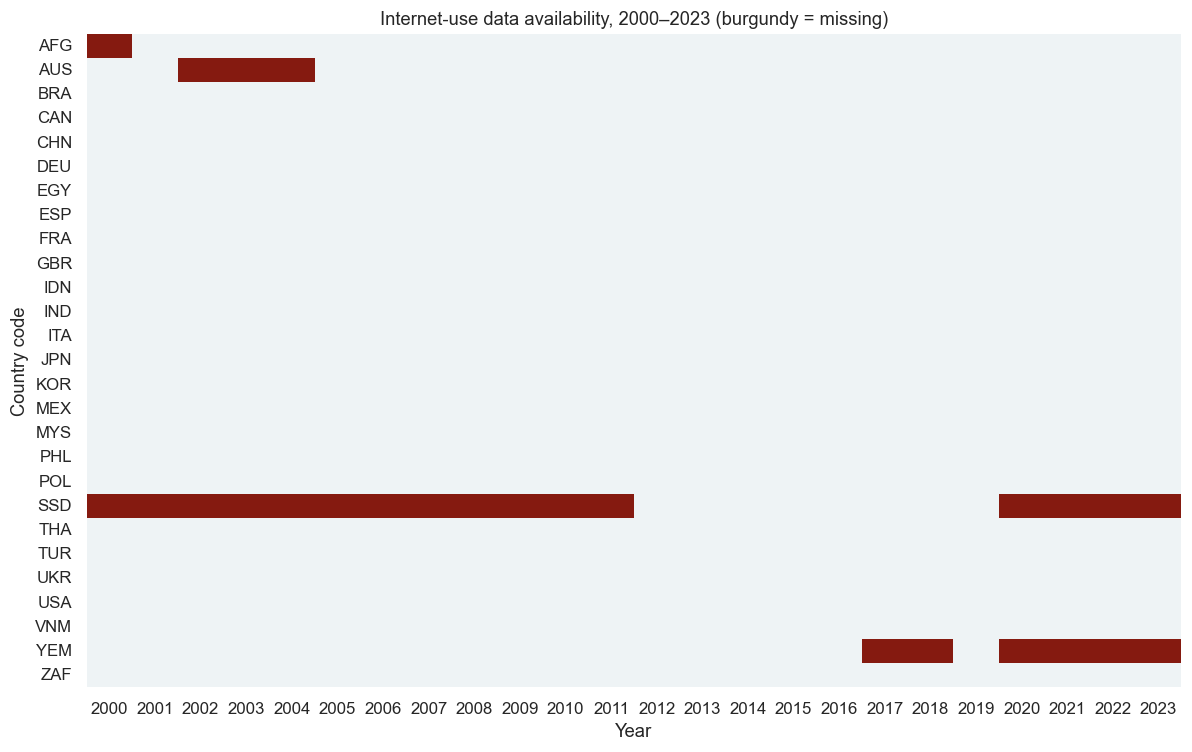

In [15]:
missing_map = panel.pivot(index="country_code", columns="year", values="internet_pct").isna().astype(int)
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(missing_map, cmap=["#eef3f5", "#851a10"], vmin=0, vmax=1, cbar=False, ax=ax)
ax.set(title="Internet-use data availability, 2000–2023 (burgundy = missing)", xlabel="Year", ylabel="Country code")
fig.tight_layout()
save_figure(fig, "06_missingness_map.png")


### 7B Small multiples
Separate panels show the same measure for six countries with common axes. This reduces line clutter and makes country trajectories easier to compare. Keep the same scale unless you clearly explain a different choice. The code plots every expected year and leaves genuine gaps visible.


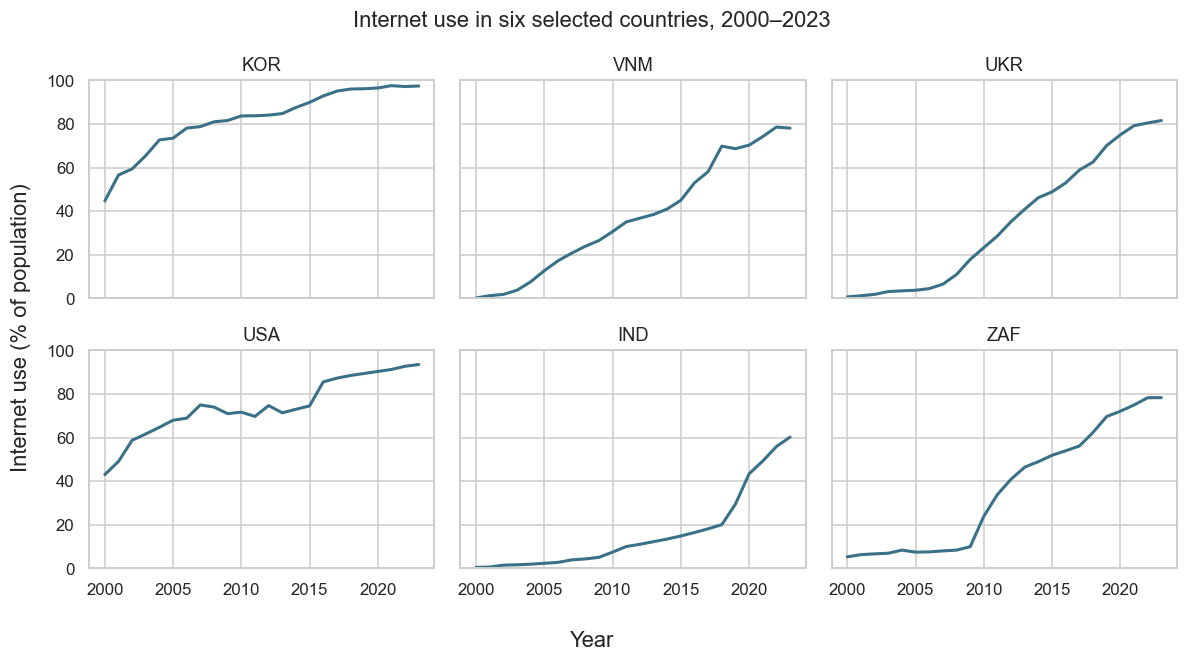

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True, sharey=True)
for ax, country in zip(axes.flat, focus_codes):
    subset = panel.loc[panel.country_code == country].set_index("year").reindex(YEARS)
    ax.plot(YEARS, subset["internet_pct"], color="#3a7188", linewidth=2)
    ax.set(title=country, ylim=(0, 100))
fig.supxlabel("Year"); fig.supylabel("Internet use (% of population)")
fig.suptitle("Internet use in six selected countries, 2000–2023")
fig.tight_layout()
save_figure(fig, "07_small_multiples.png")


### 7C A scatterplot matrix
A `pairplot` displays several pairwise relationships and marginal distributions. This example uses the **same complete-case countries for every panel**, so it answers a slightly different sample question from the pairwise correlation table. Natural-log GDP is explicit in the variable label. No significance tests or regression lines are added.


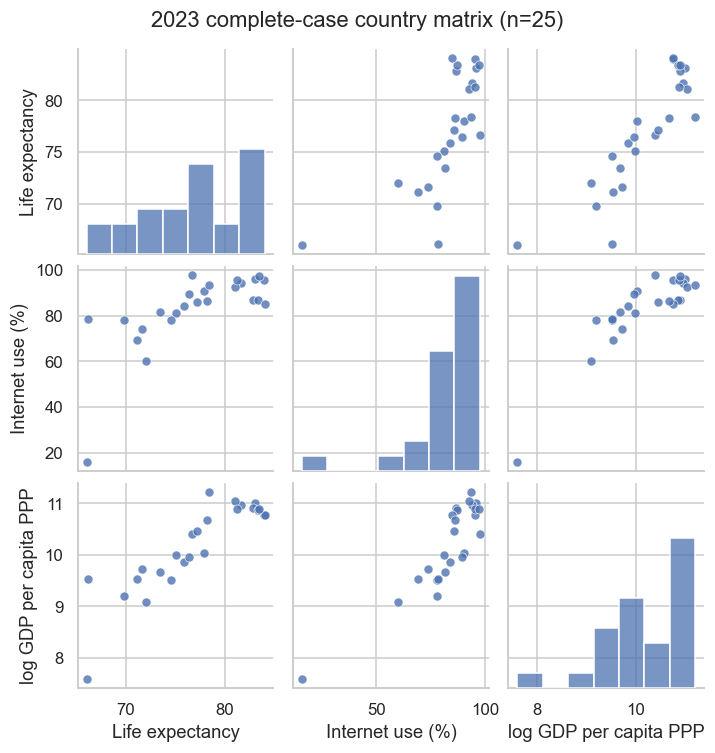

In [17]:
pair_data = complete[VALUES].copy()
pair_data["log GDP per capita PPP"] = np.log(pair_data.pop("gdp_pc_ppp"))
pair_data = pair_data.rename(columns={"life_expectancy": "Life expectancy", "internet_pct": "Internet use (%)"})
grid = sns.pairplot(pair_data, diag_kind="hist", height=2.2,
                    plot_kws={"alpha": .8, "s": 35}, diag_kws={"bins": 7})
grid.fig.suptitle(f"2023 complete-case country matrix (n={len(pair_data)})", y=1.03)
save_figure(grid.fig, "08_pairplot.png")


### 7D Endpoint changes and an empirical distribution
An endpoint comparison requires both actual endpoints. The change is in **percentage points**. If an endpoint is missing, that country is excluded from this specific change plot and reported.

An **ECDF** plots the share of observed countries at or below each value. It avoids histogram bins but still depends on the selected sample.


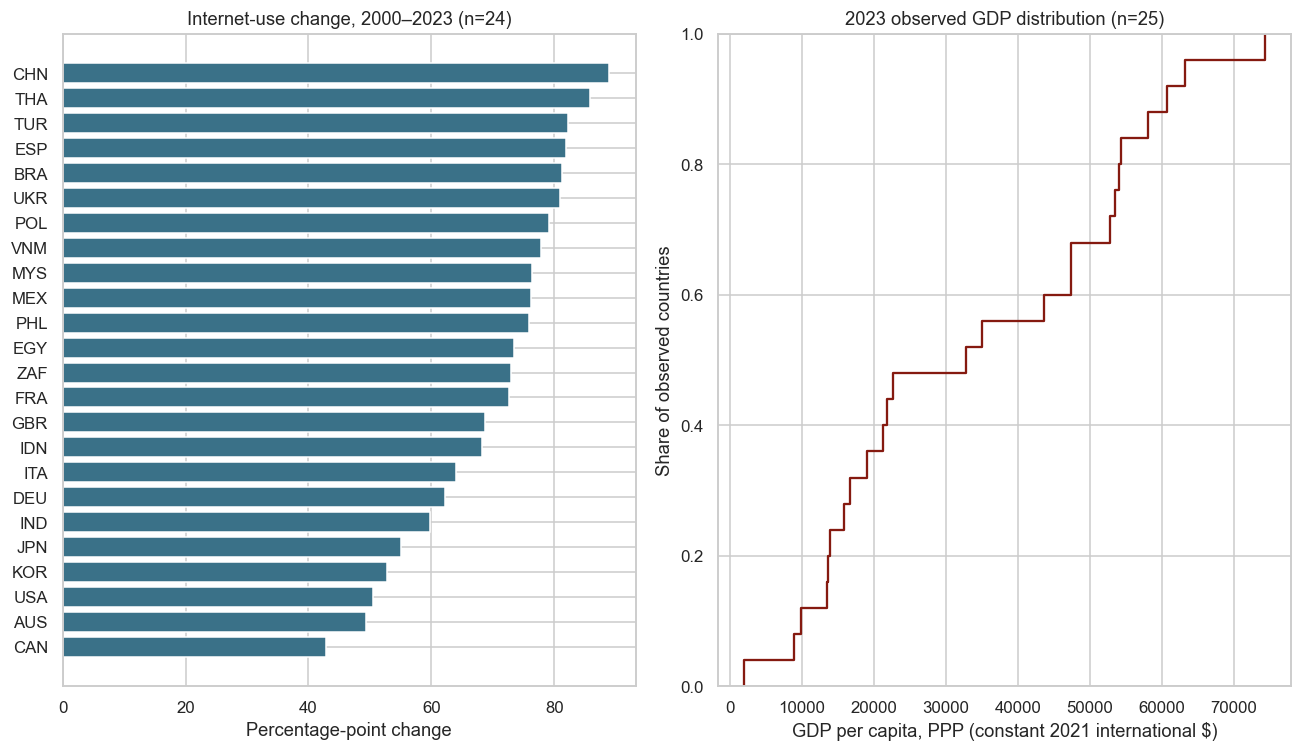

Missing endpoint pair: ['AFG', 'SSD', 'YEM']


In [18]:
changes = endpoints["change_pp_2000_2023"].dropna().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
axes[0].barh(changes.index, changes.values, color="#3a7188")
axes[0].set(title=f"Internet-use change, 2000–2023 (n={len(changes)})", xlabel="Percentage-point change")
sns.ecdfplot(data=latest, x="gdp_pc_ppp", ax=axes[1], color="#851a10")
axes[1].set(title=f"2023 observed GDP distribution (n={latest['gdp_pc_ppp'].notna().sum()})",
            xlabel="GDP per capita, PPP (constant 2021 international $)", ylabel="Share of observed countries")
fig.tight_layout()
save_figure(fig, "09_changes_ecdf.png")
print("Missing endpoint pair:", endpoints.index[endpoints["change_pp_2000_2023"].isna()].tolist())


### 7E Optional automatic profiling package
`ydata-profiling` can produce a broad local HTML report. Its availability depends on package/Python versions. It is optional; the tested custom report already provides tables and graphics without extra installation. In a separate environment, consult its current documentation before installing. In Colab, an optional installation command is `%pip install ydata-profiling`.

Review automated warnings and correlations. They do not decide which observations to delete, establish measurement validity, or create a research finding. Use a named cross-section instead of pooling repeated country-years without thought.


In [19]:
RUN_OPTIONAL_PROFILE = False
if RUN_OPTIONAL_PROFILE:
    try:
        from ydata_profiling import ProfileReport
        profile = ProfileReport(latest[VALUES], title="Selected countries in 2023", explorative=True)
        profile.to_file(str(DOCS / "optional_ydata_profile.html"))
        print("Saved local optional profile.")
    except ImportError:
        print("Optional package not installed. Core report remains available. Consult package documentation.")
else:
    print("Optional profiling package disabled; no installation required.")


Optional profiling package disabled; no installation required.


## 8 A transparent raw-to-analysis pipeline
The function below reruns the preparation from original API responses. It performs explicit reshaping and a validated join, retains missing measurements, adds a derived log measure, and returns a decision log. We confirm that it reproduces the table used above. This is the pattern to adapt for your project.

**No duplicate or outlier is deleted merely because a function marks it.** No values are imputed in this class pipeline. A different justified cleaning decision must appear in code and the log.

The output bundle includes raw responses and provenance, prepared data, source definitions, validation, descriptive tables and figures. Save/download your completed notebook separately.


In [20]:
def prepare_analysis(raw_dir):
    observations = parse_snapshot(raw_dir)
    country_names = observations[["country_code", "country"]].drop_duplicates()
    result = observations.pivot(index=KEY, columns="indicator", values="value").rename(columns=INDICATORS).reset_index()
    result.columns.name = None
    result = result.merge(country_names, on="country_code", how="left", validate="many_to_one")
    result = result[KEY + ["country"] + VALUES].sort_values(KEY).reset_index(drop=True)
    validation = validate_panel(result)
    if not validation["passes"].all():
        raise ValueError("Unresolved validation failure")
    result["log_gdp_pc_ppp"] = np.log(result["gdp_pc_ppp"].where(result["gdp_pc_ppp"] > 0))
    log = pd.DataFrame([
        ["Parse", "Read original API pages; convert year/value explicitly; check long keys", len(observations)],
        ["Reshape", "One country-year row; pivot requires unique keys", len(result)],
        ["Join", "Add country names with many-to-one validation", len(result)],
        ["Missing values", "Retain provider nulls; no imputation or global row deletion", len(result)],
        ["Derived measure", "Natural log for positive GDP; preserve original measurement", len(result)],
    ], columns=["step", "decision", "rows_after"])
    return result, validation, log

rerun, rerun_checks, decision_log = prepare_analysis(RAW)
pd.testing.assert_frame_equal(panel, rerun)
for entry in manifest["records"]:
    assert hashlib.sha256((RAW / entry["file"]).read_bytes()).hexdigest() == entry["sha256"]
panel.to_csv(PREP / "country_year_panel.csv", index=False)
latest.to_csv(PREP / "cross_section_2023.csv", index=False)
checks.to_csv(DOCS / "validation.csv", index=False)
decision_log.to_csv(DOCS / "preparation_log.csv", index=False)
dictionary = pd.DataFrame([
    {"variable": name, "definition": LABELS[name], "indicator": code,
     "source_url": "https://data.worldbank.org/indicator/" + code,
     "missing_code": "API null preserved as missing", "source": "World Bank WDI and original providers"}
    for code, name in INDICATORS.items()])
dictionary.to_csv(DOCS / "data_dictionary.csv", index=False)
(DOCS / "environment.json").write_text(json.dumps({"python": sys.version.split()[0],
    "pandas": pd.__version__, "numpy": np.__version__, "seaborn": sns.__version__}, indent=2))
(DOCS / "README.txt").write_text(
    "Real World Bank WDI API snapshot retrieved 31 October 2026. See raw_snapshot/manifest.json for exact URLs, provider update dates and hashes.\n"
    "Teaching selection of 27 countries, 2000-2023. Descriptive, unweighted country analyses. Not a representative world sample.\n"
    "Missing values retained; no imputation. Plot-specific exclusions and sample counts appear in the notebook.\n"
    "Indicator pages display CC BY 4.0. Attribute World Bank, WDI, indicator and original providers; review dataset-specific terms.\n"
    "Rerun the notebook from top to bottom with API refresh off. Optional live downloads remain separate.\n", encoding="utf-8")
BUNDLE = ROOT / "w10_analysis_outputs.zip"
with zipfile.ZipFile(BUNDLE, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in [RAW, PREP, DOCS, FIGS]:
        for file in sorted(folder.glob("*")):
            if file.is_file():
                z.write(file, arcname=file.relative_to(ROOT))
print("PASS: rerun reproduces prepared table; raw response hashes unchanged.")
print(decision_log.to_string(index=False))
print("Download from the Files sidebar:", BUNDLE)


PASS: rerun reproduces prepared table; raw response hashes unchanged.
           step                                                                decision  rows_after
          Parse Read original API pages; convert year/value explicitly; check long keys        1944
        Reshape                        One country-year row; pivot requires unique keys         648
           Join                           Add country names with many-to-one validation         648
 Missing values             Retain provider nulls; no imputation or global row deletion         648
Derived measure             Natural log for positive GDP; preserve original measurement         648
Download from the Files sidebar: c:\Users\vyshn\OneDrive - kdis.ac.kr\Documents\GitHub\Sogang\2026\Fall\Research Method of Data Science\W10\w10_lab\w10_analysis_outputs.zip


## 9 Your project studio
Use your approved project data if ready. Otherwise choose two countries and one or two measures from this real API dataset, and explain the relevance and limitations for your question. A qualitative final study may use the quantitative source for context.

**Required:**
1. Define your row unit and unique key. Keep raw data separate.
2. Show one transparent preparation operation and at least one relevant validation check. If a join is needed, declare its keys and cardinality. Do not add a join merely to tick a box.
3. State your missing-value policy and report usable sample sizes.
4. Produce a numerical summary and two suitable plots, progressing from a simple comparison to a relationship or change plot.
5. Write a 100–150 word descriptive finding with units, period, sample, limitation, and no unsupported causal claim.
6. Record one revision after peer feedback and disclose/verify any permitted AI assistance.

**Your decisions and finding:** Replace this text.

**Peer feedback and revision:** Replace this text.

**AI-use and verification statement:** Replace this text, or write “No AI assistance used.”



### Optional project starter
Set RUN_PROJECT_STARTER=True to reuse the real API data for a six-country comparison. Adapt the country list and labels to your question. This creates two plots and a summary with the same validated source records.


In [21]:
RUN_PROJECT_STARTER = False
PROJECT_CODES = ["KOR", "VNM", "UKR", "POL", "JPN", "USA"]
if RUN_PROJECT_STARTER:
    project_panel = panel.loc[panel.country_code.isin(PROJECT_CODES)].copy()
    project_2023 = project_panel.loc[project_panel.year == 2023].copy()
    numeric_summary(project_2023, VALUES).to_csv(DOCS / "project_summary_2023.csv")
    fig, ax = plt.subplots(figsize=(9, 5))
    for country in PROJECT_CODES:
        series = project_panel.loc[project_panel.country_code == country].set_index("year").reindex(YEARS)
        ax.plot(YEARS, series["internet_pct"], label=country)
    ax.set(xlabel="Year", ylabel="Internet use (%)", ylim=(0, 100), title="Student-selected countries, 2000–2023")
    ax.legend(title="Country code", ncol=2)
    save_figure(fig, "10_project_trends.png")
    observed = project_2023.dropna(subset=["gdp_pc_ppp", "life_expectancy"])
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(observed.gdp_pc_ppp, observed.life_expectancy, color="#3a7188")
    for row in observed.itertuples():
        ax.annotate(row.country_code, (row.gdp_pc_ppp, row.life_expectancy), xytext=(5, 5), textcoords="offset points")
    ax.set_xscale("log")
    ax.set(xlabel=LABELS["gdp_pc_ppp"] + " (log axis)", ylabel=LABELS["life_expectancy"],
           title=f"Student-selected countries, 2023 (n={len(observed)})")
    save_figure(fig, "11_project_relationship.png")
else:
    print("Optional project starter disabled. Enable it or adapt the provided code to approved data.")


Optional project starter disabled. Enable it or adapt the provided code to approved data.


## 10 Reproducibility and submission
Save your changes. Restart the kernel/session and run all with `REFRESH_API=False` and `RUN_OPTIONAL_PROFILE=False`. All standard plots and the custom report should still run. Raw-file hashes and the preparation rerun must pass. Download `w10_analysis_outputs.zip` and save your completed notebook. Submit through posted Cyber Campus instructions. No separate exit ticket or new grading weight is introduced.

## References
- World Bank [WDI API](https://datahelpdesk.worldbank.org/knowledgebase/articles/889392-about-the-indicators-api) and [call structures](https://datahelpdesk.worldbank.org/knowledgebase/articles/898581-api-basic-call-structures)
- [GDP per capita PPP](https://data.worldbank.org/indicator/NY.GDP.PCAP.PP.KD), [life expectancy](https://data.worldbank.org/indicator/SP.DYN.LE00.IN), [internet use](https://data.worldbank.org/indicator/IT.NET.USER.ZS)
- [World Bank dataset terms](https://www.worldbank.org/ext/en/legal/terms-conditions/datasets)
- [pandas describe](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html), [merge](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html)
- [seaborn pairplot](https://seaborn.pydata.org/generated/seaborn.pairplot.html), [YData Profiling](https://docs.profiling.ydata.ai/latest/)

Data attribution: World Bank, World Development Indicators, listed indicator codes, and underlying providers identified in archived API metadata. Indicator pages and documentation checked October 2026.


**Final export:** Run the next cell after adding your own tables and plots. It refreshes the bundle so those outputs are included. Your written answers remain in the notebook, which you must save separately.


In [22]:
with zipfile.ZipFile(BUNDLE, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in [RAW, PREP, DOCS, FIGS]:
        for file in sorted(folder.glob("*")):
            if file.is_file():
                z.write(file, arcname=file.relative_to(ROOT))
print("Refreshed output bundle:", BUNDLE)
print("Save/download the completed notebook separately.")


Refreshed output bundle: c:\Users\vyshn\OneDrive - kdis.ac.kr\Documents\GitHub\Sogang\2026\Fall\Research Method of Data Science\W10\w10_lab\w10_analysis_outputs.zip
Save/download the completed notebook separately.
